# Clean vs Dirty Street Photos: Logistic Regression
Group activity. Members: Randel Serafica, Trishia Joy Rirao.

**Question:** can a few simple numbers measured from a street photo (brightness, colour, edges)
predict whether the photo shows a dirty street (1) or a clean street (0)?

**Data:** Kaggle "Clean/Littered Road Classification" (Md Faizal Karim, Krishnav Rajbangshi).
237 photos and `metadata.csv` with `filename,label`.

**How to run:** put `archive.zip` in the same folder as this notebook (in Colab, upload it
with the Files panel), then choose Run all. The notebook unzips it by itself.

## 1. Setup

In [1]:
import os, zipfile, hashlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score)

SEED = 42                      # fixed so everyone gets the same split and numbers
ZIP_PATH = next((p for p in ("archive.zip", "../archive.zip") if os.path.exists(p)), "archive.zip")   # the Kaggle download
DATA_DIR = "data"              # where it is unzipped
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

if not os.path.isdir(os.path.join(DATA_DIR, "Images")):
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(DATA_DIR)

IMG_DIR = os.path.join(DATA_DIR, "Images", "Images")
meta = pd.read_csv(os.path.join(DATA_DIR, "metadata.csv"))
RESULTS = {}   # we collect key numbers here for the report

## 2. First look at the data

In [2]:
print("rows, columns in metadata.csv:", meta.shape)
print(meta.head())
print()
print("missing values per column:\n", meta.isna().sum())
print("duplicate file names:", meta["filename"].duplicated().sum())
missing_files = [f for f in meta["filename"] if not os.path.exists(os.path.join(IMG_DIR, f))]
print("files listed but not found:", len(missing_files))

counts = meta["label"].value_counts().sort_index()
pct = (counts / len(meta) * 100).round(1)
print("\nclass counts (0 = clean, 1 = dirty):\n", counts.to_string())
print("class percentages:\n", pct.to_string())
RESULTS["rows"] = int(len(meta))
RESULTS["n_clean"] = int(counts[0]); RESULTS["n_dirty"] = int(counts[1])
RESULTS["pct_clean"] = float(pct[0]); RESULTS["pct_dirty"] = float(pct[1])

rows, columns in metadata.csv: (237, 2)
        filename  label
0    dirty_2.jpg      1
1   clean_36.jpg      0
2   clean_31.jpg      0
3   dirty_69.jpg      1
4  clean_113.jpg      0

missing values per column:
 filename    0
label       0
dtype: int64
duplicate file names: 0
files listed but not found: 0

class counts (0 = clean, 1 = dirty):
 label
0    113
1    124
class percentages:
 label
0    47.7
1    52.3


## 3. Turn each photo into a row of numbers
A photo is not a table, so we measure it. Each photo is shrunk to 256 x 192 pixels so every
photo is measured the same way. The features are:

| Feature | What it measures |
| --- | --- |
| `brightness` | average brightness (0 dark, 1 bright) |
| `saturation` | average colour strength (0 grey, 1 vivid) |
| `contrast` | spread of grey levels (flat scene or mixed scene) |
| `edge_density` | share of pixels on a sharp edge (clutter and detail) |
| `colour_entropy` | how many different colours are mixed (higher means more variety) |
| `green_share` | share of green pixels (trees, grass) |
| `grey_share` | share of grey pixels (road, concrete) |

We also record the original width and height, but we do **not** use them as features. We only
use them later to check that the photo size is not secretly giving the answer away.

In [3]:
def measure(path):
    raw = open(path, "rb").read()
    im = Image.open(path).convert("RGB")
    w, h = im.size
    small = im.resize((256, 192))
    rgb = np.asarray(small, dtype=float) / 255
    hsv = np.asarray(small.convert("HSV"), dtype=float) / 255
    gray = np.asarray(small.convert("L"), dtype=float) / 255
    H, S, V = hsv[..., 0], hsv[..., 1], hsv[..., 2]

    gy, gx = np.gradient(gray)
    edge_density = (np.hypot(gx, gy) > 0.10).mean()

    q = (rgb * 4).clip(0, 3.999).astype(int)               # 4 levels per colour = 64 colour bins
    codes = q[..., 0] * 16 + q[..., 1] * 4 + q[..., 2]
    p = np.bincount(codes.ravel(), minlength=64) / codes.size
    p = p[p > 0]
    colour_entropy = float(-(p * np.log2(p)).sum())

    green_share = float(((H > 0.18) & (H < 0.45) & (S > 0.2) & (V > 0.2)).mean())
    grey_share = float(((S < 0.15) & (V > 0.2) & (V < 0.9)).mean())

    ahash = np.asarray(im.convert("L").resize((16, 16)), dtype=float)
    ahash = "".join("1" if v else "0" for v in (ahash > ahash.mean()).ravel())

    return dict(brightness=V.mean(), saturation=S.mean(), contrast=gray.std(),
                edge_density=edge_density, colour_entropy=colour_entropy,
                green_share=green_share, grey_share=grey_share,
                orig_width=w, orig_height=h,
                md5=hashlib.md5(raw).hexdigest(), ahash=ahash)

rows = [measure(os.path.join(IMG_DIR, f)) for f in meta["filename"]]
df = pd.concat([meta, pd.DataFrame(rows)], axis=1)
FEATURES = ["brightness", "saturation", "contrast", "edge_density",
            "colour_entropy", "green_share", "grey_share"]
print(df[["filename", "label"] + FEATURES].head())
print("\nrows x columns after adding features:", df.shape)

        filename  label  brightness  saturation  contrast  edge_density  \
0    dirty_2.jpg      1    0.472711    0.141740  0.189156      0.151835   
1   clean_36.jpg      0    0.535561    0.272711  0.253759      0.146139   
2   clean_31.jpg      0    0.601506    0.358516  0.199436      0.135518   
3   dirty_69.jpg      1    0.449088    0.153063  0.178753      0.213420   
4  clean_113.jpg      0    0.440438    0.441351  0.226363      0.271993   

   colour_entropy  green_share  grey_share  
0        3.070369     0.020223    0.687032  
1        3.556029     0.040019    0.259766  
2        3.425611     0.176412    0.142843  
3        2.980441     0.022420    0.570821  
4        3.789856     0.291504    0.124451  

rows x columns after adding features: (237, 13)


## 4. Clean the data: duplicates and strange values

In [4]:
exact_dups = int(df["md5"].duplicated().sum())
near_dups = int(df["ahash"].duplicated().sum())
print("exact duplicate files (same bytes):", exact_dups)
print("near duplicates (same 16x16 picture pattern):", near_dups)
dup_mask = df["ahash"].duplicated(keep=False)
if dup_mask.any():
    print(df.loc[dup_mask, ["filename", "label", "orig_width", "orig_height"]]
            .sort_values("filename").to_string())

# drop repeats so the same picture cannot be in both training and testing
before = len(df)
df = df.drop_duplicates(subset="ahash", keep="first").reset_index(drop=True)
print(f"\nrows before: {before}, after removing repeats: {len(df)}")
RESULTS["exact_dups"] = exact_dups; RESULTS["near_dups"] = near_dups
RESULTS["rows_after_dedup"] = int(len(df))

# outliers: values more than 3 standard deviations from the mean
z = (df[FEATURES] - df[FEATURES].mean()) / df[FEATURES].std()
out_counts = (z.abs() > 3).sum()
print("\nvalues beyond 3 standard deviations, per feature:\n", out_counts.to_string())
print("photos with at least one such value:", int((z.abs() > 3).any(axis=1).sum()))
RESULTS["outlier_photos"] = int((z.abs() > 3).any(axis=1).sum())
print("\nsmallest and largest original image sizes (pixels):",
      int(df['orig_width'].min()), "x", int(df['orig_height'].min()), "to",
      int(df['orig_width'].max()), "x", int(df['orig_height'].max()))

exact duplicate files (same bytes): 6
near duplicates (same 16x16 picture pattern): 8
          filename  label  orig_width  orig_height
213   clean_46.jpg      0        1240          930
25    clean_54.jpg      0        1240          930
225   clean_56.jpg      0        1000          430
130   clean_82.jpg      0        1000          430
199  dirty_108.jpg      1        1200          900
187  dirty_110.jpg      1        2048         1536
155  dirty_115.jpg      1        1024          664
222  dirty_117.jpg      1        2048         1536
15   dirty_118.jpg      1        1024          664
119   dirty_14.jpg      1         800          533
69    dirty_16.jpg      1         800          533
14    dirty_22.jpg      1         640          480
87    dirty_32.jpg      1        1280          720
77    dirty_38.jpg      1        2048         1536
131   dirty_54.jpg      1        1280          720

rows before: 237, after removing repeats: 229

values beyond 3 standard deviations, per feature:


**Decision.** Repeated pictures are removed. We keep the outliers, because they are real photos
(for example a very dark or very colourful scene), not mistakes, and the model scales every
feature before fitting.

All seven features are numbers, so nothing needed to be turned into numbers. If we had a
categorical column (for example "city"), we would turn it into 0/1 columns (one-hot encoding).

## 5. Visualizations

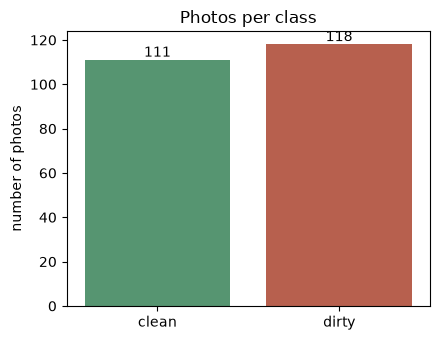

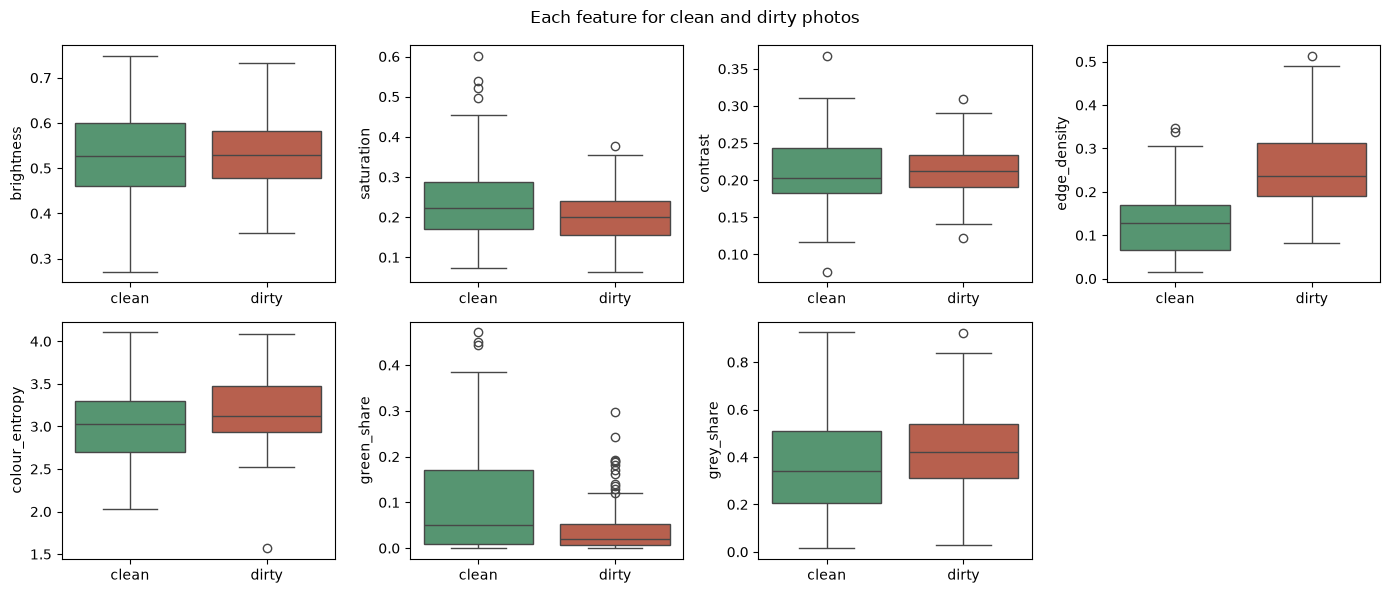

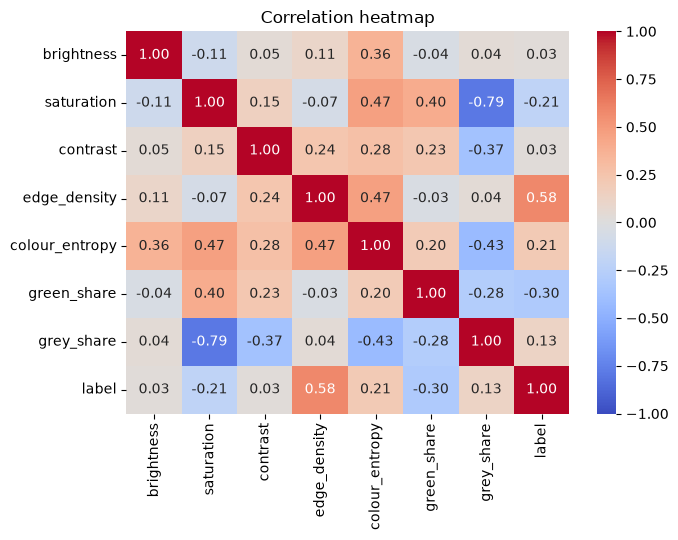

correlation of each feature with 'dirty':
 edge_density      0.58
green_share      -0.30
colour_entropy    0.21
saturation       -0.21
grey_share        0.13
brightness        0.03
contrast          0.03

feature pairs with |correlation| >= 0.6:
  saturation and grey_share: -0.79


In [5]:
df["class"] = df["label"].map({0: "clean", 1: "dirty"})
PAL = {"clean": "#4C9F70", "dirty": "#C8553D"}   # green = clean, red = dirty

# Chart 1: how many photos per class
fig, ax = plt.subplots(figsize=(4.5, 3.5))
sns.countplot(data=df, x="class", order=["clean", "dirty"], hue="class",
              palette=PAL, legend=False, ax=ax)
for c in ax.containers:
    ax.bar_label(c)
ax.set_title("Photos per class"); ax.set_xlabel(""); ax.set_ylabel("number of photos")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/1_class_counts.png", dpi=150); plt.show()

# Chart 2: features, clean vs dirty
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, f in zip(axes.ravel(), FEATURES):
    sns.boxplot(data=df, x="class", y=f, order=["clean", "dirty"], hue="class",
                palette=PAL, legend=False, ax=ax)
    ax.set_xlabel("")
axes.ravel()[-1].axis("off")
plt.suptitle("Each feature for clean and dirty photos")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/2_feature_boxplots.png", dpi=150); plt.show()

# Chart 3: correlation heatmap (features and the label)
corr = df[FEATURES + ["label"]].corr()
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation heatmap")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/3_correlation_heatmap.png", dpi=150); plt.show()

with_label = corr["label"].drop("label").sort_values(key=abs, ascending=False)
print("correlation of each feature with 'dirty':\n", with_label.round(2).to_string())
pairs = [(a, b, corr.loc[a, b]) for i, a in enumerate(FEATURES) for b in FEATURES[i + 1:]
         if abs(corr.loc[a, b]) >= 0.6]
print("\nfeature pairs with |correlation| >= 0.6:")
for a, b, r in sorted(pairs, key=lambda t: -abs(t[2])):
    print(f"  {a} and {b}: {r:.2f}")
RESULTS["corr_with_label"] = {k: round(float(v), 3) for k, v in with_label.items()}
RESULTS["corr_pairs"] = [[a, b, round(float(r), 3)] for a, b, r in pairs]

## 6. Target balance

In [6]:
vc = df["label"].value_counts().sort_index()
n = len(df)
print(f"clean: {vc[0]} ({vc[0]/n*100:.1f}%)   dirty: {vc[1]} ({vc[1]/n*100:.1f}%)")
majority = vc.max() / n
print(f"always guessing the bigger class would be right {majority*100:.1f}% of the time")
RESULTS["majority_acc"] = round(float(majority), 4)
RESULTS["pct_clean_final"] = round(float(vc[0] / n * 100), 1)
RESULTS["pct_dirty_final"] = round(float(vc[1] / n * 100), 1)

clean: 111 (48.5%)   dirty: 118 (51.5%)
always guessing the bigger class would be right 51.5% of the time


## 7. Train and test the logistic regression
80% of the photos train the model and 20% are kept hidden to test it. The split keeps the
clean/dirty mix the same in both parts (`stratify`).

In [7]:
X = df[FEATURES]; y = df["label"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y)
print("training photos:", len(X_train), " testing photos:", len(X_test))

model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
model.fit(X_train, y_train)

def report(model, Xa, ya, threshold=0.5):
    prob = model.predict_proba(Xa)[:, 1]
    pred = (prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(ya, pred, labels=[0, 1]).ravel()
    return dict(threshold=threshold, tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp),
                accuracy=accuracy_score(ya, pred),
                precision=precision_score(ya, pred, zero_division=0),
                recall=recall_score(ya, pred, zero_division=0),
                f1=f1_score(ya, pred, zero_division=0))

train_rep = report(model, X_train, y_train)
test_rep = report(model, X_test, y_test)
print("TRAIN accuracy: %.3f" % train_rep["accuracy"])
print("TEST  accuracy: %.3f" % test_rep["accuracy"])
RESULTS["train_acc"] = round(train_rep["accuracy"], 4)
RESULTS["test"] = {k: (round(v, 4) if isinstance(v, float) else v) for k, v in test_rep.items()}
RESULTS["n_train"] = int(len(X_train)); RESULTS["n_test"] = int(len(X_test))
RESULTS["auc_test"] = round(float(roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])), 4)

training photos: 183  testing photos: 46
TRAIN accuracy: 0.852
TEST  accuracy: 0.826


### Confusion matrix (test set)

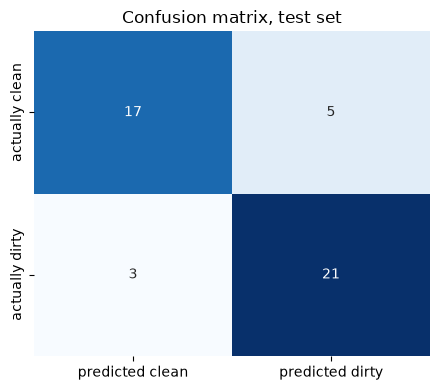

true negatives (clean called clean): 17
false positives (clean called dirty): 5
false negatives (dirty called clean): 3
true positives (dirty called dirty):  21

accuracy  0.826
precision 0.808
recall    0.875
f1-score  0.840
AUC       0.892


In [8]:
cm = np.array([[test_rep["tn"], test_rep["fp"]], [test_rep["fn"], test_rep["tp"]]])
fig, ax = plt.subplots(figsize=(4.5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["predicted clean", "predicted dirty"],
            yticklabels=["actually clean", "actually dirty"], ax=ax)
ax.set_title("Confusion matrix, test set")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/4_confusion_matrix.png", dpi=150); plt.show()
print(f"true negatives (clean called clean): {test_rep['tn']}")
print(f"false positives (clean called dirty): {test_rep['fp']}")
print(f"false negatives (dirty called clean): {test_rep['fn']}")
print(f"true positives (dirty called dirty):  {test_rep['tp']}")
print()
print("accuracy  %.3f" % test_rep["accuracy"])
print("precision %.3f" % test_rep["precision"])
print("recall    %.3f" % test_rep["recall"])
print("f1-score  %.3f" % test_rep["f1"])
print("AUC       %.3f" % RESULTS["auc_test"])

### Coefficients
The features were scaled first, so each coefficient means: "when this feature goes up by one
standard deviation, the log-odds of 'dirty' change by this amount, other features held
constant". The odds ratio is `exp(coefficient)`; above 1 means more likely dirty.

intercept: 0.164
       feature  coefficient  odds_ratio
  edge_density        2.047       7.742
   green_share       -0.988       0.372
    saturation       -0.563       0.570
    grey_share       -0.344       0.709
    brightness       -0.210       0.811
      contrast       -0.167       0.846
colour_entropy        0.137       1.147


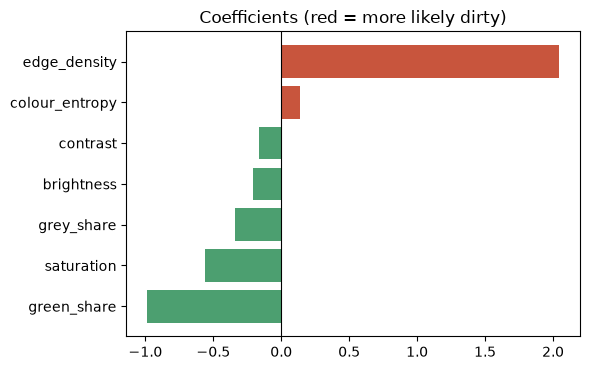

In [9]:
lr = model.named_steps["logisticregression"]
coef = pd.DataFrame({"feature": FEATURES, "coefficient": lr.coef_[0],
                     "odds_ratio": np.exp(lr.coef_[0])}).sort_values(
                     "coefficient", key=abs, ascending=False).reset_index(drop=True)
print("intercept: %.3f" % lr.intercept_[0])
print(coef.round(3).to_string(index=False))
RESULTS["intercept"] = round(float(lr.intercept_[0]), 3)
RESULTS["coef"] = [[r.feature, round(float(r.coefficient), 3), round(float(r.odds_ratio), 3)]
                   for r in coef.itertuples()]

fig, ax = plt.subplots(figsize=(6, 3.8))
c = coef.sort_values("coefficient")
ax.barh(c["feature"], c["coefficient"], color=["#C8553D" if v > 0 else "#4C9F70" for v in c["coefficient"]])
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Coefficients (red = more likely dirty)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/5_coefficients.png", dpi=150); plt.show()

## 8. Threshold: what changes if we raise or lower 0.5?

In [10]:
rows_t = [report(model, X_test, y_test, t) for t in (0.3, 0.5, 0.7)]
tt = pd.DataFrame(rows_t)[["threshold", "tn", "fp", "fn", "tp",
                           "accuracy", "precision", "recall", "f1"]]
print(tt.round(3).to_string(index=False))
RESULTS["thresholds"] = [{k: (round(v, 3) if isinstance(v, float) else v) for k, v in r.items()}
                         for r in rows_t]

 threshold  tn  fp  fn  tp  accuracy  precision  recall    f1
       0.3  14   8   1  23     0.804      0.742   0.958 0.836
       0.5  17   5   3  21     0.826      0.808   0.875 0.840
       0.7  20   2   7  17     0.804      0.895   0.708 0.791


## 9. Is the model overfitting? Is the score stable?
With only a few dozen test photos one lucky split can change the score a lot, so we also run
5-fold cross-validation (five different train/test splits) and compare with the majority-class
guess.

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_scores = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
                            X, y, cv=cv, scoring="accuracy")
print("5-fold accuracies:", cv_scores.round(3))
print("mean %.3f, spread (std) %.3f" % (cv_scores.mean(), cv_scores.std()))
print("train accuracy %.3f vs test accuracy %.3f (gap %.3f)" % (
    train_rep["accuracy"], test_rep["accuracy"], train_rep["accuracy"] - test_rep["accuracy"]))
RESULTS["cv"] = [round(float(v), 3) for v in cv_scores]
RESULTS["cv_mean"] = round(float(cv_scores.mean()), 4); RESULTS["cv_std"] = round(float(cv_scores.std()), 4)

5-fold accuracies: [0.804 0.804 0.87  0.761 0.822]
mean 0.812, spread (std) 0.035
train accuracy 0.852 vs test accuracy 0.826 (gap 0.026)


## 10. Honesty check: can the photo size alone predict the label?
If original width and height predict the label well, then the data has a hidden shortcut
(for example the clean photos came from a different website than the dirty ones). This would
make our results look better than they are.

In [12]:
size_X = df[["orig_width", "orig_height"]].assign(ratio=df["orig_width"] / df["orig_height"])
size_cv = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
                          size_X, y, cv=cv, scoring="accuracy")
print("accuracy from image size alone (5-fold): %.3f" % size_cv.mean())
print("compare: always guessing the bigger class: %.3f" % majority)
RESULTS["size_only_acc"] = round(float(size_cv.mean()), 4)

accuracy from image size alone (5-fold): 0.563
compare: always guessing the bigger class: 0.515


## 11. One improvement
Two features that move together (for example `contrast` and `edge_density`) make the
coefficients hard to trust. We drop the weaker one of every pair with correlation above 0.7
and compare before and after, using both the single test split and 5-fold cross-validation.

In [13]:
to_drop = set()
for a, b, r in pairs:
    if abs(r) >= 0.7:
        weaker = a if abs(corr.loc[a, "label"]) < abs(corr.loc[b, "label"]) else b
        to_drop.add(weaker)
kept = [f for f in FEATURES if f not in to_drop]
print("features dropped:", sorted(to_drop) or "none")
print("features kept:", kept)

if to_drop:
    m2 = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    m2.fit(X_train[kept], y_train)
    r2 = report(m2, X_test[kept], y_test)
    cv2 = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
                          X[kept], y, cv=cv, scoring="accuracy")
    comp = pd.DataFrame({
        "": ["before (all 7 features)", "after (correlated feature dropped)"],
        "test accuracy": [test_rep["accuracy"], r2["accuracy"]],
        "test precision": [test_rep["precision"], r2["precision"]],
        "test recall": [test_rep["recall"], r2["recall"]],
        "test F1": [test_rep["f1"], r2["f1"]],
        "5-fold mean accuracy": [cv_scores.mean(), cv2.mean()]})
    print(comp.round(3).to_string(index=False))
    RESULTS["improve"] = {"dropped": sorted(to_drop), "after_test": {k: round(float(v), 4) for k, v in r2.items()},
                          "after_cv_mean": round(float(cv2.mean()), 4)}
else:
    print("No pair was correlated above 0.7, so we try a different threshold instead (see section 8).")
    RESULTS["improve"] = {"dropped": []}

features dropped: ['grey_share']
features kept: ['brightness', 'saturation', 'contrast', 'edge_density', 'colour_entropy', 'green_share']
                                    test accuracy  test precision  test recall  test F1  5-fold mean accuracy
           before (all 7 features)          0.826           0.808        0.875    0.840                 0.812
after (correlated feature dropped)          0.848           0.840        0.875    0.857                 0.817


## 12. Save the key numbers

In [14]:
with open("results.json", "w") as f:
    json.dump(RESULTS, f, indent=2, default=float)
print(json.dumps(RESULTS, indent=2, default=float)[:1500])

{
  "rows": 237,
  "n_clean": 113,
  "n_dirty": 124,
  "pct_clean": 47.7,
  "pct_dirty": 52.3,
  "exact_dups": 6,
  "near_dups": 8,
  "rows_after_dedup": 229,
  "outlier_photos": 12,
  "corr_with_label": {
    "edge_density": 0.584,
    "green_share": -0.302,
    "colour_entropy": 0.211,
    "saturation": -0.209,
    "grey_share": 0.129,
    "brightness": 0.028,
    "contrast": 0.026
  },
  "corr_pairs": [
    [
      "saturation",
      "grey_share",
      -0.795
    ]
  ],
  "majority_acc": 0.5153,
  "pct_clean_final": 48.5,
  "pct_dirty_final": 51.5,
  "train_acc": 0.8525,
  "test": {
    "threshold": 0.5,
    "tn": 17,
    "fp": 5,
    "fn": 3,
    "tp": 21,
    "accuracy": 0.8261,
    "precision": 0.8077,
    "recall": 0.875,
    "f1": 0.84
  },
  "n_train": 183,
  "n_test": 46,
  "auc_test": 0.892,
  "intercept": 0.164,
  "coef": [
    [
      "edge_density",
      2.047,
      7.742
    ],
    [
      "green_share",
      -0.988,
      0.372
    ],
    [
      "saturation",
    